In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

print("Libraries imported successfully")

In [4]:
df = pd.read_csv("/content/final_data.csv")


In [5]:
df.head()

,Document,Topic_group
0,timecard error and not able to submit the time...,HR Support
1,re open configuration re configuration hi goin...,Access
2,stolen laptop en stolen laptop en dear please ...,Hardware
3,badge lost sent friday badge lost dear unfortu...,Access
4,add to confluence space thursday pm setup dear...,Access


In [6]:

# Dataset dimensions
print("Shape:", df.shape)

# Column information
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

Shape: (3000, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Document     3000 non-null   object
 1   Topic_group  3000 non-null   object
dtypes: object(2)
memory usage: 47.0+ KB

Missing values:
Document       0
Topic_group    0
dtype: int64

Duplicate records: 0


In [7]:
print(df['Topic_group'].value_counts())

print("\nCategory percentages:")
print(df['Topic_group'].value_counts(normalize=True) * 100)

Topic_group
Hardware      1150
HR Support     871
Access         565
Storage        213
Purchase       201
Name: count, dtype: int64

Category percentages:
Topic_group
Hardware      38.333333
HR Support    29.033333
Access        18.833333
Storage        7.100000
Purchase       6.700000
Name: proportion, dtype: float64


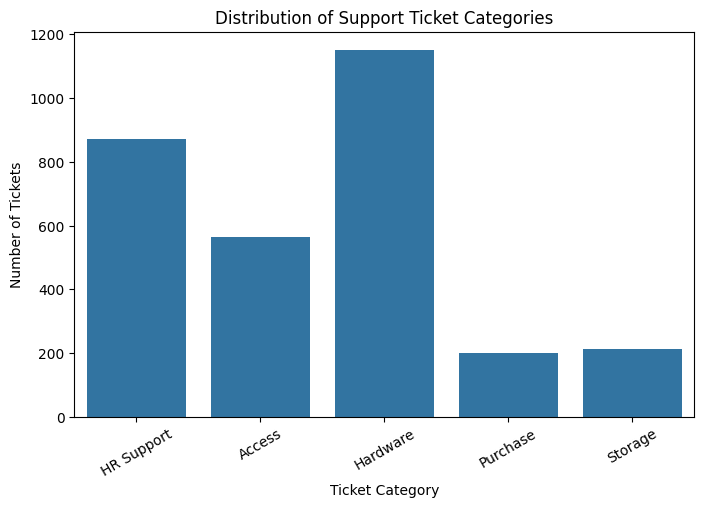

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Topic_group')

plt.title("Distribution of Support Ticket Categories")
plt.xlabel("Ticket Category")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=30)

plt.show()

In [11]:
def clean_text(text):

    text = str(text)

    text = text.lower()

    text = re.sub(r'http\S+|www\S+', '', text)

    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text).strip()

    return text


df['cleaned_document'] = df['Document'].apply(clean_text)

display(df[['Document', 'cleaned_document', 'Topic_group']].head())

,Document,cleaned_document,Topic_group
0,timecard error and not able to submit the time...,timecard error and not able to submit the time...,HR Support
1,re open configuration re configuration hi goin...,re open configuration re configuration hi goin...,Access
2,stolen laptop en stolen laptop en dear please ...,stolen laptop en stolen laptop en dear please ...,Hardware
3,badge lost sent friday badge lost dear unfortu...,badge lost sent friday badge lost dear unfortu...,Access
4,add to confluence space thursday pm setup dear...,add to confluence space thursday pm setup dear...,Access


In [12]:
df.head()

,Document,Topic_group,cleaned_document
0,timecard error and not able to submit the time...,HR Support,timecard error and not able to submit the time...
1,re open configuration re configuration hi goin...,Access,re open configuration re configuration hi goin...
2,stolen laptop en stolen laptop en dear please ...,Hardware,stolen laptop en stolen laptop en dear please ...
3,badge lost sent friday badge lost dear unfortu...,Access,badge lost sent friday badge lost dear unfortu...
4,add to confluence space thursday pm setup dear...,Access,add to confluence space thursday pm setup dear...


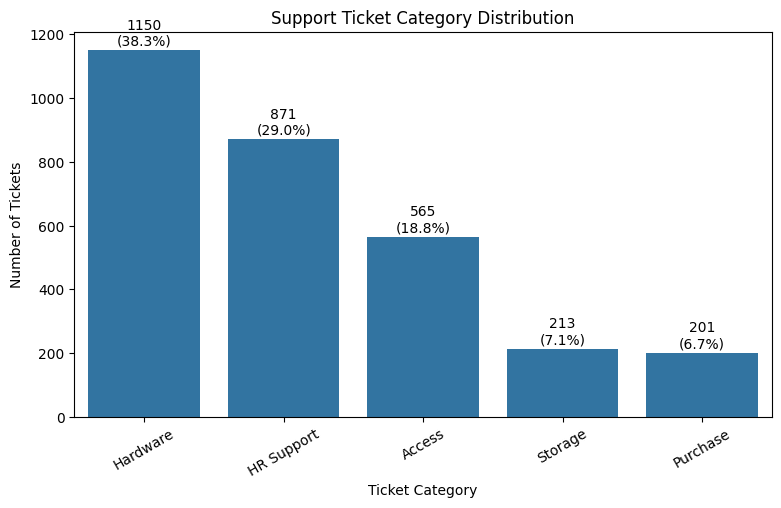

In [13]:
category_counts = df['Topic_group'].value_counts()

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

for i, value in enumerate(category_counts.values):
    percentage = value / len(df) * 100
    ax.text(i, value + 15, f'{value}\n({percentage:.1f}%)',
            ha='center')

plt.title('Support Ticket Category Distribution')
plt.xlabel('Ticket Category')
plt.ylabel('Number of Tickets')
plt.xticks(rotation=30)
plt.show()

### Observation: Support Ticket Category Distribution

The category distribution graph illustrates the distribution of 3,000 support tickets across five categories.

Hardware represents the largest category with 1,150 records (38.3%), followed by HR Support with 871 records (29%). Access contributes 565 records (18.8%), while Storage and Purchase have considerably fewer records, accounting for 7.1% and 6.7%, respectively.

**Conclusion:**

The dataset exhibits class imbalance, as Hardware and HR Support dominate the majority of records, whereas Storage and Purchase are underrepresented. This imbalance may influence the classification model towards majority categories.

To address this issue, we will investigate class-balancing techniques and evaluate model performance using macro F1-score and class-wise precision and recall.


In [18]:
# Calculate number of characters in each ticket

df['text_length'] = df['Document'].astype(str).apply(len)

# Display statistics

df['text_length'].describe()

,text_length
count,3000.000000
mean,286.072333
std,373.120451
min,12.000000
25%,109.000000
50%,173.000000
75%,293.000000
max,6120.000000


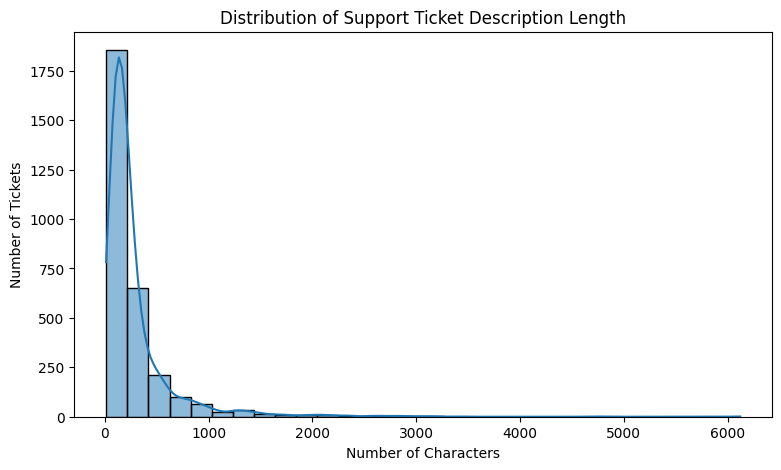

In [19]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='text_length',
    bins=30,
    kde=True
)

plt.title('Distribution of Support Ticket Description Length')
plt.xlabel('Number of Characters')
plt.ylabel('Number of Tickets')

plt.show()

### Observation: Distribution of Support Ticket Description Length

The histogram illustrates the distribution of character lengths across 3,000 support ticket descriptions.

The distribution is positively skewed (right-skewed), indicating that most ticket descriptions are relatively short, while a smaller number contain considerably longer text.

The average description length is approximately 286 characters, whereas the median is 173 characters. The difference between the mean and median indicates the influence of longer descriptions on the average.

The minimum description length is 12 characters, while the maximum is 6,120 characters. The standard deviation of 373.12 indicates considerable variation in description lengths.

**Conclusion:**

The dataset contains ticket descriptions of varying lengths, with most descriptions being relatively short and a few being considerably longer.

This variation needs to be considered during text preprocessing and feature extraction.

**Action:**
We will inspect unusually long and short descriptions to identify irrelevant content or formatting issues. We will avoid removing long descriptions automatically because they may contain useful information for classification.


In [20]:
avg_length = df.groupby('Topic_group')['text_length'].mean().sort_values(ascending=False)

print(avg_length)

Topic_group
Hardware      356.520000
HR Support    250.486797
Access        239.791150
Purchase      233.407960
Storage       223.699531
Name: text_length, dtype: float64


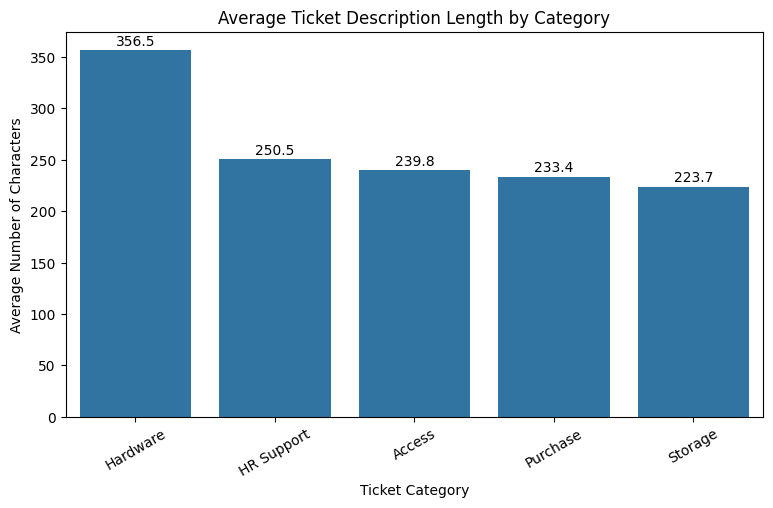

In [21]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=avg_length.index,
    y=avg_length.values
)

for i, value in enumerate(avg_length.values):
    ax.text(i, value + 5, f'{value:.1f}', ha='center')

plt.title('Average Ticket Description Length by Category')
plt.xlabel('Ticket Category')
plt.ylabel('Average Number of Characters')
plt.xticks(rotation=30)

plt.show()

### Observation: Average Ticket Description Length by Category

Hardware has the highest average description length (356.52 characters), whereas Storage has the lowest (223.70 characters). HR Support, Access and Purchase have average lengths of 250.49, 239.79 and 233.41 characters, respectively.

**Conclusion:** Hardware tickets tend to contain more detailed descriptions, while Storage tickets are comparatively shorter. This highlights variations in text length across support categories, which should be considered during text preprocessing and feature extraction.


In [22]:
from collections import Counter

all_words = ' '.join(
    df['Document'].astype(str).str.lower()
).split()

word_counts = Counter(all_words)

common_words = pd.DataFrame(
    word_counts.most_common(15),
    columns=['Word', 'Frequency']
)

display(common_words)

,Word,Frequency
0,please,4201
1,pm,1760
2,regards,1724
3,hi,1699
4,thank,1494
5,hello,1442
6,for,1400
7,re,1351
8,you,1330
9,thanks,1246


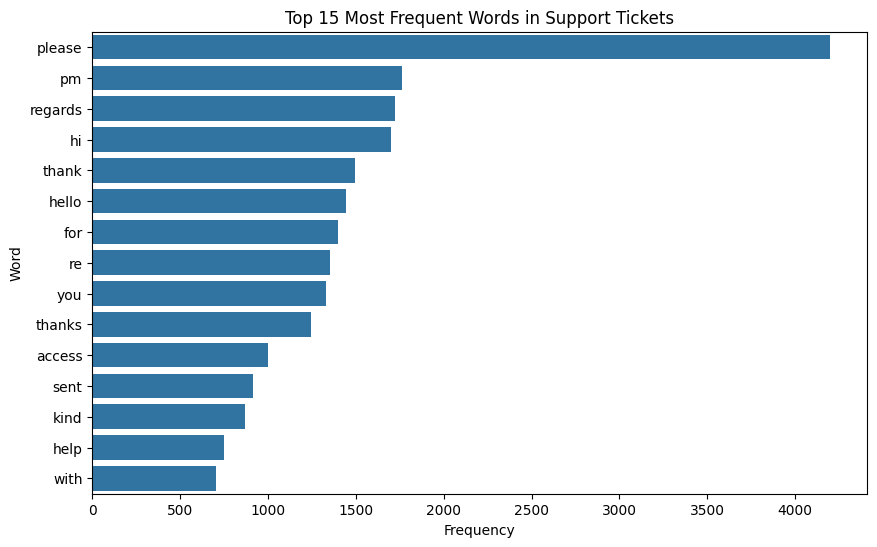

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=common_words,
    x='Frequency',
    y='Word'
)

plt.title('Top 15 Most Frequent Words in Support Tickets')
plt.xlabel('Frequency')
plt.ylabel('Word')

plt.show()

### Observation: Most Frequent Words in Support Tickets

The word-frequency analysis identifies the 15 most frequently occurring words in ticket descriptions.

* **"please"** is the most frequent word, appearing 4,201 times.
* Communication-related words such as "hi", "hello", "thank", "thanks" and "regards" occur frequently.
* Words such as "access" and "help" provide useful context about support requests.

**Conclusion:**

The dataset contains many conversational and email-style expressions. These words may not contribute significantly to ticket classification.

**Action:**

During text preprocessing, we will remove common stopwords and unnecessary conversational expressions while preserving meaningful technical keywords that help distinguish ticket categories.


In [24]:
for i in range(5):
    print(f"Ticket {i+1}:")
    print(df['Document'].iloc[i])
    print("-" * 80)

Ticket 1:
timecard error and not able to submit the timecard called regarding timecard being error have helped her enter holiday code submit her timecards
--------------------------------------------------------------------------------
Ticket 2:
re open configuration re configuration hi going cr order add please assign queue best regards senior engineer re configuration hi thanks update mo visibility related user connect he except edge which fine user edge user wants anywhere configuration configured also configuration let related configuration environment site role cluster name back back edge edge front front front file mediation mediation persistent chat persistent chat persistent chat persistent chat persistent chat cluster name back back edge edge front front front file mediation mediation persistent chat persistent chat persistent chat persistent chat persistent chat add networks configuration please let make change best regards re configuration hi pushed users none mentioned push

In [26]:
import nltk
nltk.download('stopwords')

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

# Preserve negation words
stop_words -= {'not', 'no', 'nor'}

def remove_stopwords(text):
    words = text.split()
    filtered_words = [
        word for word in words if word not in stop_words
    ]
    return ' '.join(filtered_words)

# Create a separate processed column
df['processed_document'] = df['cleaned_document'].apply(remove_stopwords)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [27]:
df.head()

,Document,Topic_group,cleaned_document,text_length,processed_document
0,timecard error and not able to submit the time...,HR Support,timecard error and not able to submit the time...,144,timecard error not able submit timecard called...
1,re open configuration re configuration hi goin...,Access,re open configuration re configuration hi goin...,1085,open configuration configuration hi going cr o...
2,stolen laptop en stolen laptop en dear please ...,Hardware,stolen laptop en stolen laptop en dear please ...,268,stolen laptop en stolen laptop en dear please ...
3,badge lost sent friday badge lost dear unfortu...,Access,badge lost sent friday badge lost dear unfortu...,143,badge lost sent friday badge lost dear unfortu...
4,add to confluence space thursday pm setup dear...,Access,add to confluence space thursday pm setup dear...,167,add confluence space thursday pm setup dear st...


In [28]:
from sklearn.model_selection import train_test_split

X = df['processed_document']
y = df['Topic_group']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining category distribution:")
print(y_train.value_counts())

print("\nTesting category distribution:")
print(y_test.value_counts())

Training data: (2400,)
Testing data: (600,)

Training category distribution:
Topic_group
Hardware      920
HR Support    697
Access        452
Storage       170
Purchase      161
Name: count, dtype: int64

Testing category distribution:
Topic_group
Hardware      230
HR Support    174
Access        113
Storage        43
Purchase       40
Name: count, dtype: int64


In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [30]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

In [31]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [32]:
X_test_tfidf = tfidf.transform(X_test)

In [33]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

print("Vocabulary size:", len(tfidf.vocabulary_))

Training TF-IDF shape: (2400, 5000)
Testing TF-IDF shape: (600, 5000)
Vocabulary size: 5000


### Feature Engineering – TF-IDF Vectorization

TF-IDF (Term Frequency–Inverse Document Frequency) was applied to convert textual ticket descriptions into numerical feature representations.

The vectorizer was configured with a maximum of 5,000 features, unigrams and bigrams, a minimum document frequency of 2, and a maximum document frequency of 95%.

The resulting feature matrices are:

* Training data: 2,400 × 5,000
* Testing data: 600 × 5,000

**Conclusion:**

The textual data has been successfully transformed into numerical features, making it suitable for machine learning classification algorithms. The same vocabulary and feature representation were maintained across training and testing datasets to prevent data leakage.


In [34]:
from imblearn.over_sampling import RandomOverSampler

In [35]:
!pip install imbalanced-learn

In [36]:
print(y_train.value_counts())

Topic_group
Hardware      920
HR Support    697
Access        452
Storage       170
Purchase      161
Name: count, dtype: int64


In [37]:
ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train_tfidf,
    y_train
)

In [38]:
print("Before balancing:")
print(y_train.value_counts())

print("\nAfter balancing:")
print(y_train_balanced.value_counts())

print("\nBalanced training shape:", X_train_balanced.shape)

Before balancing:
Topic_group
Hardware      920
HR Support    697
Access        452
Storage       170
Purchase      161
Name: count, dtype: int64

After balancing:
Topic_group
Hardware      920
HR Support    920
Access        920
Storage       920
Purchase      920
Name: count, dtype: int64

Balanced training shape: (4600, 5000)


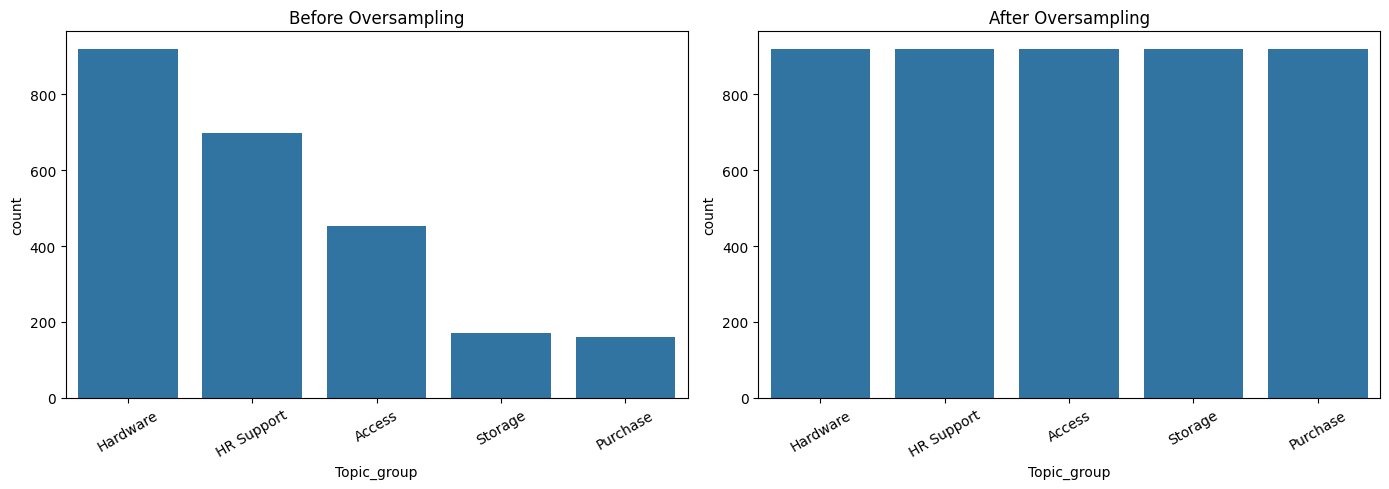

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before Oversampling")
axes[0].tick_params(axis='x', rotation=30)

sns.countplot(x=y_train_balanced, ax=axes[1])
axes[1].set_title("After Oversampling")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [40]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_tfidf,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training shape:", X_train_final.shape)
print("Validation shape:", X_val.shape)

print("\nTraining category distribution:")
print(y_train_final.value_counts())

print("\nValidation category distribution:")
print(y_val.value_counts())

Training shape: (1920, 5000)
Validation shape: (480, 5000)

Training category distribution:
Topic_group
Hardware      736
HR Support    558
Access        361
Storage       136
Purchase      129
Name: count, dtype: int64

Validation category distribution:
Topic_group
Hardware      184
HR Support    139
Access         91
Storage        34
Purchase       32
Name: count, dtype: int64


In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score

# Create model
lr_without = LogisticRegression(max_iter=1000, random_state=42)

# Train model
lr_without.fit(X_train_final, y_train_final)

# Predict validation data
y_pred_without = lr_without.predict(X_val)

# Evaluate
print("Accuracy:", accuracy_score(y_val, y_pred_without))
print("Macro F1:", f1_score(y_val, y_pred_without, average='macro'))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_without))

Accuracy: 0.7958333333333333
Macro F1: 0.7804607054445077

Classification Report:
              precision    recall  f1-score   support

      Access       0.91      0.68      0.78        91
  HR Support       0.83      0.79      0.81       139
    Hardware       0.71      0.92      0.80       184
    Purchase       1.00      0.59      0.75        32
     Storage       1.00      0.62      0.76        34

    accuracy                           0.80       480
   macro avg       0.89      0.72      0.78       480
weighted avg       0.82      0.80      0.79       480



In [42]:
results = []

results.append({
    'Experiment': 'Without Balancing',
    'Accuracy': accuracy_score(y_val, y_pred_without),
    'Macro F1': f1_score(y_val, y_pred_without, average='macro')
})

In [44]:
lr_weighted = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr_weighted.fit(X_train_final, y_train_final)

y_pred_weighted = lr_weighted.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred_weighted))
print("Macro F1:", f1_score(y_val, y_pred_weighted, average='macro'))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_weighted))

Accuracy: 0.8479166666666667
Macro F1: 0.8614161650301178

Classification Report:
              precision    recall  f1-score   support

      Access       0.87      0.81      0.84        91
  HR Support       0.87      0.80      0.83       139
    Hardware       0.80      0.90      0.85       184
    Purchase       0.89      0.78      0.83        32
     Storage       0.97      0.94      0.96        34

    accuracy                           0.85       480
   macro avg       0.88      0.85      0.86       480
weighted avg       0.85      0.85      0.85       480



In [45]:
results.append({
    'Experiment': 'Class Weighting',
    'Accuracy': accuracy_score(y_val, y_pred_weighted),
    'Macro F1': f1_score(y_val, y_pred_weighted, average='macro')
})

In [46]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train_final,
    y_train_final
)

print("Before oversampling:")
print(y_train_final.value_counts())

print("\nAfter oversampling:")
print(y_train_ros.value_counts())

Before oversampling:
Topic_group
Hardware      736
HR Support    558
Access        361
Storage       136
Purchase      129
Name: count, dtype: int64

After oversampling:
Topic_group
Hardware      736
HR Support    736
Purchase      736
Access        736
Storage       736
Name: count, dtype: int64


In [47]:
lr_ros = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_ros.fit(X_train_ros, y_train_ros)

y_pred_ros = lr_ros.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred_ros))
print("Macro F1:", f1_score(y_val, y_pred_ros, average='macro'))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_ros))

Accuracy: 0.8520833333333333
Macro F1: 0.8654785849676717

Classification Report:
              precision    recall  f1-score   support

      Access       0.89      0.85      0.87        91
  HR Support       0.86      0.81      0.84       139
    Hardware       0.80      0.89      0.84       184
    Purchase       0.92      0.75      0.83        32
     Storage       0.97      0.94      0.96        34

    accuracy                           0.85       480
   macro avg       0.89      0.85      0.87       480
weighted avg       0.86      0.85      0.85       480



In [48]:
results.append({
    'Experiment': 'Random Oversampling',
    'Accuracy': accuracy_score(y_val, y_pred_ros),
    'Macro F1': f1_score(y_val, y_pred_ros, average='macro')
})

In [49]:
results_df = pd.DataFrame(results)
print(results_df.sort_values(by='Macro F1', ascending=False))

            Experiment  Accuracy  Macro F1
2  Random Oversampling  0.852083  0.865479
1      Class Weighting  0.847917  0.861416
0    Without Balancing  0.795833  0.780461


In [50]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Create model
svm_model = LinearSVC(random_state=42)

# Train using oversampled data
svm_model.fit(X_train_ros, y_train_ros)

# Predict validation data
y_pred_svm = svm_model.predict(X_val)

# Evaluate
print("Accuracy:", accuracy_score(y_val, y_pred_svm))
print("Macro F1:", f1_score(y_val, y_pred_svm, average='macro'))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_svm))

Accuracy: 0.8458333333333333
Macro F1: 0.8635199049316696

Classification Report:
              precision    recall  f1-score   support

      Access       0.87      0.85      0.86        91
  HR Support       0.83      0.81      0.82       139
    Hardware       0.83      0.85      0.84       184
    Purchase       0.90      0.88      0.89        32
     Storage       0.91      0.91      0.91        34

    accuracy                           0.85       480
   macro avg       0.87      0.86      0.86       480
weighted avg       0.85      0.85      0.85       480



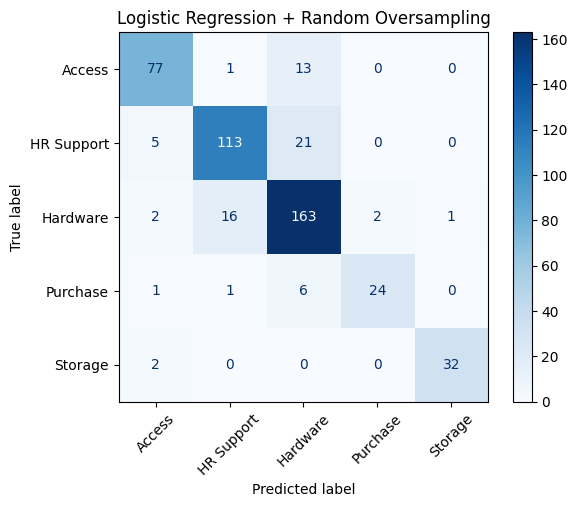

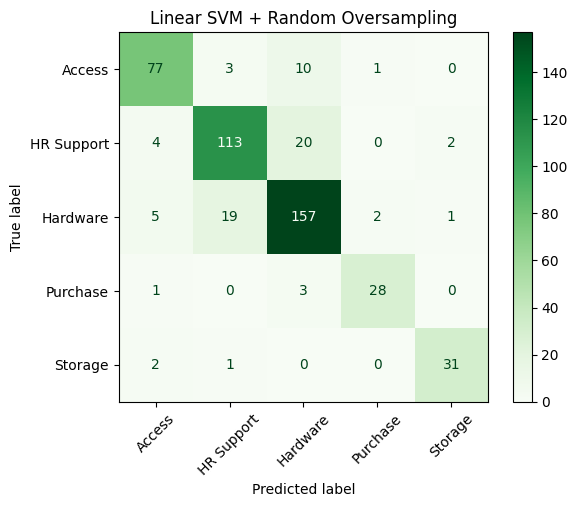

In [51]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define category labels
labels = sorted(y_val.unique())

# Logistic Regression confusion matrix
cm_lr = confusion_matrix(y_val, y_pred_ros, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=labels
)

disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("Logistic Regression + Random Oversampling")
plt.show()


# Linear SVM confusion matrix
cm_svm = confusion_matrix(y_val, y_pred_svm, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=labels
)

disp.plot(cmap='Greens', xticks_rotation=45)
plt.title("Linear SVM + Random Oversampling")
plt.show()

### Confusion Matrix Analysis

We compared two machine learning models using confusion matrices to understand their classification performance across all five ticket categories.

**1. Logistic Regression with Random Oversampling**

* Correctly classified 409 out of 480 validation tickets.
* Performed well in identifying Hardware (163/184) and Storage (32/34) tickets.
* Some Hardware tickets were incorrectly classified as HR Support (16 cases).
* Some Access tickets were incorrectly classified as Hardware (13 cases).

**2. Linear SVM with Random Oversampling**

* Correctly classified 406 out of 480 validation tickets.
* Performed particularly well in identifying Purchase tickets (28/32).
* Some Hardware tickets were incorrectly classified as HR Support (19 cases).
* Some Access tickets were incorrectly classified as Hardware (10 cases).

**3. Comparative Analysis**

| Metric                | Logistic Regression | Linear SVM |
| --------------------- | ------------------: | ---------: |
| Correct predictions   |                 409 |        406 |
| Incorrect predictions |                  71 |         74 |
| Accuracy              |              85.21% |     84.58% |
| Macro F1-score        |              0.8655 |     0.8635 |

**Conclusion:**

Both models demonstrated good classification performance. Logistic Regression with Random Oversampling achieved slightly higher accuracy and Macro F1-score than Linear SVM. Therefore, Logistic Regression with Random Oversampling was selected as our leading candidate for final model evaluation.


In [52]:
from imblearn.over_sampling import RandomOverSampler

final_ros = RandomOverSampler(random_state=42)

X_train_final_balanced, y_train_final_balanced = final_ros.fit_resample(
    X_train_tfidf,
    y_train
)

print("Before balancing:")
print(y_train.value_counts())

print("\nAfter balancing:")
print(y_train_final_balanced.value_counts())

print("\nFinal training shape:", X_train_final_balanced.shape)

Before balancing:
Topic_group
Hardware      920
HR Support    697
Access        452
Storage       170
Purchase      161
Name: count, dtype: int64

After balancing:
Topic_group
Hardware      920
HR Support    920
Access        920
Storage       920
Purchase      920
Name: count, dtype: int64

Final training shape: (4600, 5000)


In [53]:
from sklearn.linear_model import LogisticRegression

# Create final model
final_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train on balanced data
final_model.fit(
    X_train_final_balanced,
    y_train_final_balanced
)

print("Final Logistic Regression model trained successfully!")

Final Logistic Regression model trained successfully!


Final Test Accuracy: 0.8783333333333333
Final Test Macro F1: 0.8870586833084936

Final Classification Report:
              precision    recall  f1-score   support

      Access       0.90      0.82      0.86       113
  HR Support       0.87      0.87      0.87       174
    Hardware       0.84      0.92      0.88       230
    Purchase       1.00      0.90      0.95        40
     Storage       0.95      0.81      0.88        43

    accuracy                           0.88       600
   macro avg       0.91      0.87      0.89       600
weighted avg       0.88      0.88      0.88       600



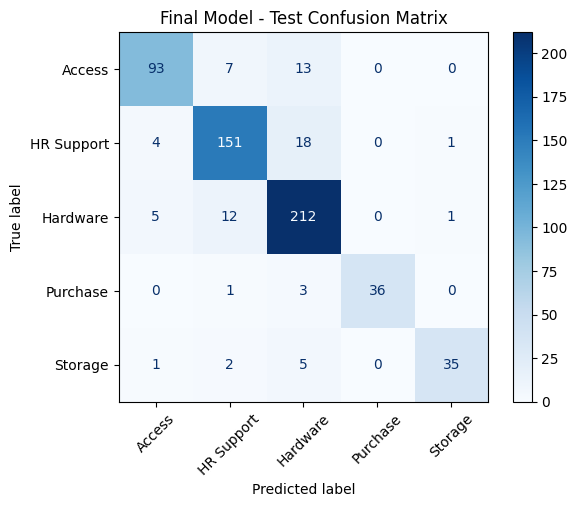

In [54]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
import matplotlib.pyplot as plt

# Predict test data
y_pred_final = final_model.predict(X_test_tfidf)

# Calculate metrics
print("Final Test Accuracy:",
      accuracy_score(y_test, y_pred_final))

print("Final Test Macro F1:",
      f1_score(y_test, y_pred_final, average='macro'))

# Classification report
print("\nFinal Classification Report:")
print(classification_report(y_test, y_pred_final))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=final_model.classes_
)

disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("Final Model - Test Confusion Matrix")
plt.show()

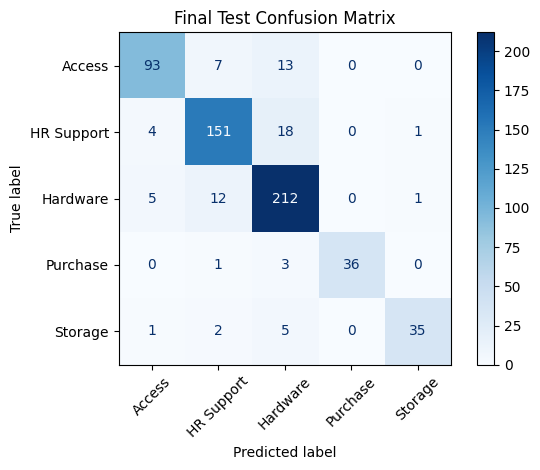

[[ 93   7  13   0   0]
 [  4 151  18   0   1]
 [  5  12 212   0   1]
 [  0   1   3  36   0]
 [  1   2   5   0  35]]


In [65]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate predictions using the already-trained final model
y_pred_final = final_model.predict(X_test_tfidf)

# Calculate test confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_final,
    labels=final_model.classes_
)

# Display
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=final_model.classes_
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Final Test Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(cm)

## Final Model Evaluation on Test Dataset

After comparing multiple approaches, Logistic Regression with TF-IDF features and Random Oversampling was selected as the final model.

The model was retrained using the complete original training dataset of 2,400 records after applying Random Oversampling. It was then evaluated on 600 previously unseen test records.

### Final Performance Metrics

* Accuracy: 87.83%
* Macro F1-score: 0.8871
* Weighted F1-score: 0.88

### Category-wise Performance

The model achieved its highest F1-score for Purchase (0.95), followed by Hardware (0.88), Storage (0.88), HR Support (0.87), and Access (0.86).

### Key Findings

* The model successfully identifies most Hardware tickets, achieving a recall of 0.92.
* Purchase classification demonstrates high precision and recall.
* Access and Hardware tickets show some classification overlap.
* HR Support classification demonstrates balanced performance.

### Conclusion

The final Logistic Regression model with TF-IDF and Random Oversampling achieved 87.83% accuracy and a Macro F1-score of 0.8871 on the unseen test dataset.

The results indicate that the model can effectively automate the categorisation of IT support tickets across five categories.


In [55]:
import joblib

# Save the trained Logistic Regression model
joblib.dump(final_model, 'ticket_classifier.pkl')

# Save the fitted TF-IDF vectorizer
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Model saved successfully!
TF-IDF vectorizer saved successfully!


In [56]:
joblib.dump(final_model, 'ticket_classifier.pkl')

['ticket_classifier.pkl']

In [57]:
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

['tfidf_vectorizer.pkl']

In [58]:
import os

print(os.listdir())

['.config', 'final_data.csv', 'ticket_classifier.pkl', 'tfidf_vectorizer.pkl', 'sample_data']


In [59]:
# Load saved model
loaded_model = joblib.load('ticket_classifier.pkl')

# Load saved vectorizer
loaded_tfidf = joblib.load('tfidf_vectorizer.pkl')

print("Both files loaded successfully!")

Both files loaded successfully!


In [60]:
sample_ticket = "I am unable to access my company laptop"

# Apply the same preprocessing used during training
cleaned_ticket = clean_text(sample_ticket)

processed_ticket = remove_stopwords(cleaned_ticket)

# Convert text into TF-IDF features
ticket_vector = loaded_tfidf.transform([processed_ticket])

# Predict category
prediction = loaded_model.predict(ticket_vector)

print("Ticket:", sample_ticket)
print("Predicted Category:", prediction[0])

Ticket: I am unable to access my company laptop
Predicted Category: Hardware


In [64]:
import joblib
import os
import shutil
from google.colab import files

# --------------------------------
# 1. Save trained ML model
# --------------------------------
joblib.dump(final_model, 'ticket_classifier.joblib')

# --------------------------------
# 2. Save fitted TF-IDF vectorizer
# --------------------------------
joblib.dump(tfidf, 'tfidf_vectorizer.joblib')

# --------------------------------
# 3. Create preprocessing.py
# --------------------------------
preprocessing_code = '''
import re
import nltk
from nltk.corpus import stopwords

try:
    stop_words = set(stopwords.words('english'))
except LookupError:
    nltk.download('stopwords')
    stop_words = set(stopwords.words('english'))

stop_words -= {'not', 'no', 'nor'}

def clean_text(text):
    text = str(text)
    text = text.lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'http\\S+|www\\S+', ' ', text)
    text = re.sub(r'\\S+@\\S+', ' ', text)
    text = re.sub(r'[^a-zA-Z0-9\\s]', ' ', text)
    text = re.sub(r'\\s+', ' ', text).strip()
    return text

def remove_stopwords(text):
    words = text.split()
    filtered_words = [
        word for word in words if word not in stop_words
    ]
    return ' '.join(filtered_words)
'''

with open('preprocessing.py', 'w') as f:
    f.write(preprocessing_code)

# --------------------------------
# 4. Create model_metrics.txt
# --------------------------------
metrics = """
PROJECT: IT Support Ticket Classification

FINAL MODEL:
Logistic Regression

FEATURE EXTRACTION:
TF-IDF Vectorizer

MAX FEATURES: 5000
NGRAM RANGE: (1, 2)
MIN_DF: 2
MAX_DF: 0.95

CLASS BALANCING:
Random Oversampling

ORIGINAL DATASET: 3000 records
ORIGINAL TRAINING DATA: 2400 records
BALANCED TRAINING DATA: 4600 records
TEST DATA: 600 records

FINAL TEST PERFORMANCE:
Accuracy: 87.83%
Macro F1 Score: 0.8871
Weighted F1 Score: 0.88

CLASSIFICATION CATEGORIES:
1. Hardware
2. HR Support
3. Access
4. Storage
5. Purchase
"""

with open('model_metrics.txt', 'w') as f:
    f.write(metrics)

# --------------------------------

# --------------------------------
# 5. Save the original dataset
# --------------------------------

df.to_csv('support_tickets.csv', index=False)

print("Dataset saved successfully!")

# --------------------------------
# 6. Download all six files
# --------------------------------
download_files = [
    'ticket_classifier.joblib',
    'tfidf_vectorizer.joblib',
    'preprocessing.py',
    'model_metrics.txt',
    'support_tickets.csv'
]

for file in download_files:
    print("Downloading:", file)
    files.download(file)

print("All files prepared successfully!")

Dataset saved successfully!
Downloading: ticket_classifier.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: tfidf_vectorizer.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

Downloading: support_tickets.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All files prepared successfully!
